In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d

In [4]:
image = np.array([
    [1, 2, 1, 0, 1],
    [0, 1, 2, 1, 0],
    [1, 0, 1, 2, 1],
    [2, 1, 0, 1, 2],
    [1, 1, 2, 0, 1]
], dtype=float)

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=float)

feature_map = correlate2d(image, kernel, mode="valid")
print("Image shape:", image.shape)
print("Kernel shape:", kernel.shape)
print("Feature map:\n", feature_map)

Image shape: (5, 5)
Kernel shape: (3, 3)
Feature map:
 [[-2.  0.  2.]
 [ 0. -2.  0.]
 [ 1. -1. -1.]]


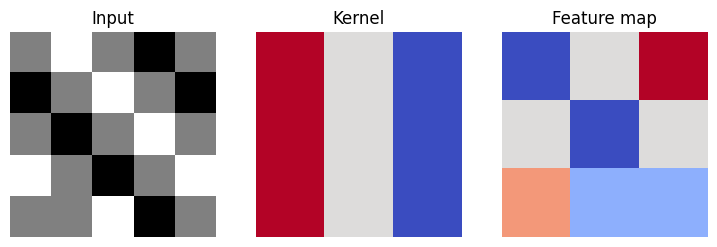

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(image, cmap="gray"); axes[0].set_title("Input")
axes[1].imshow(kernel, cmap="coolwarm"); axes[1].set_title("Kernel")
axes[2].imshow(feature_map, cmap="coolwarm"); axes[2].set_title("Feature map")
for ax in axes: ax.axis("off")
plt.show()

**1. Mengamati ukuran output**

In [7]:
def output_size(input_size, kernel_size, padding=0, stride=1):
    return (input_size + 2 * padding - kernel_size) // stride + 1

print("Valid, stride 1:", output_size(28, 3, padding=0, stride=1))
print("Same, stride 1 :", output_size(28, 3, padding=1, stride=1))
print("Valid, stride 2:", output_size(28, 3, padding=0, stride=2))

Valid, stride 1: 26
Same, stride 1 : 28
Valid, stride 2: 13


**2. Convolution dengan TensorFlow**

In [9]:
import tensorflow as tf

In [10]:
input_tensor = tf.constant(image[None, :, :, None], dtype=tf.float32)
kernel_tensor = tf.constant(kernel[:, :, None, None], dtype=tf.float32)

# tf.nn.conv2d menggunakan operasi cross-correlation
valid_output = tf.nn.conv2d(input_tensor, kernel_tensor, strides=1, padding="VALID")
same_output = tf.nn.conv2d(input_tensor, kernel_tensor, strides=1, padding="SAME")

print("VALID shape:", valid_output.shape)
print("SAME shape :", same_output.shape)

VALID shape: (1, 3, 3, 1)
SAME shape : (1, 5, 5, 1)
